# VardiyaWatt: 15 dakika sonrası için enerji tahmini
**Hazırlayan: Görkem Vatansever**  
Python proje envanteri · Regresyon · Gerçek işletme verisi

**Amaç:** Son ölçümlerden bir sonraki 15 dakikalık dönemin enerji tüketimini (kWh) tahmin etmek,
sonucu kullanıcının tanımladığı dönem bütçesiyle karşılaştırmak.

**Çalıştırma:** Colab'da `Çalışma zamanı > Tümünü çalıştır` seçeneğini kullanın. GPU gerekmez.
CSV aynı klasördeyse onu okur, yoksa resmi UCI kaynağından otomatik indirir.
Son hücredeki kutuyu işaretlerseniz uygulama sizden girdi ister.


## Aşama 1 · Problem ve proje planı
**Soru:** Önceki 15 dakika, 1 saat ve 24 saat önceki dönemlerin tüketimi ile hedef dönemin
saat/hafta sonu bilgisi, sonraki dönemin tüketimini tahmin etmeye yeterli mi?

**Hedef:** `Usage_kWh`. **Tür:** Sayısal tahmin (regresyon). **Kullanıcı:** İşletme enerji sorumlusu.
Özgün uygulama katkısı, açık veriyi kısa vadeli tahmin problemine dönüştürmek ve kullanıcıya
tanımlanabilir bir enerji bütçesi uyarısı sunmaktır. Dünyada ilk olma iddiası yoktur.

**Plan:** Kaynak ve temizlik → veri keşfi → zaman sıralı eğitim/test → basit referansla karşılaştırma → mini uygulama ve teslim.
Başarı ölçütü MAE'dir. R² tamamlayıcı ölçüttür, doğruluk yüzdesi olarak yorumlanmaz.


In [1]:
from pathlib import Path
import io, zipfile, urllib.request, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Bu paketler Colab'da hazırdır. GPU ve ek kurulum gerekmez.
CIKTI = Path('ciktilar')
CIKTI.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'figure.dpi':120})


## Aşama 2 · Veri kaynağı ve hazırlama
**Veri:** Steel Industry Energy Consumption, UCI Machine Learning Repository, veri seti 851.
DAEWOO Steel Co. Ltd (Gwangyang, Güney Kore) kaynaklı gerçek işletme kayıtlarıdır.
Veri üreticileri: Sathishkumar V E, Changsun Shin ve Yongyun Cho (2021).

- Kaynak: https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption
- DOI: https://doi.org/10.24432/C52G8C
- Lisans: CC BY 4.0 (kaynak göstererek yeniden kullanım ve uyarlama).
- Bu projedeki değişiklikler: gece yarısı zaman düzeltmesi, geçmiş tüketim özellikleri, yeni regresyon hedefi ve bütçe uyarısı.

UCI sayfasında `Load_Type` sınıf etiketi de bulunur. Bu proje, özgün bir regresyon
sorusu kurarak `Usage_kWh` sütununu hedef seçer. Aynı dönemin CO₂, reaktif enerji,
güç faktörü ve yük sınıfını tahmin girdisi olarak kullanmaz; bunlar tahmin anında bilinmeyebilir.


In [2]:
VERI_URL = 'https://archive.ics.uci.edu/static/public/851/steel+industry+energy+consumption.zip'
csv_yolu = Path('Steel_industry_data.csv')
if csv_yolu.exists():
    ham_baytlar = csv_yolu.read_bytes()
    print('Veri yerel CSV dosyasından okundu.')
else:
    # Kayıt/giriş gerektirmeyen resmi veri kaynağı.
    with urllib.request.urlopen(VERI_URL, timeout=60) as yanit:
        arsiv = zipfile.ZipFile(io.BytesIO(yanit.read()))
        ham_baytlar = arsiv.read('Steel_industry_data.csv')
    csv_yolu.write_bytes(ham_baytlar)
    print('Veri resmi UCI kaynağından indirildi.')

ham = pd.read_csv(io.BytesIO(ham_baytlar))
print('Ham veri boyutu:', ham.shape)
print('SHA256:', hashlib.sha256(ham_baytlar).hexdigest())
print(ham.head(3).to_string(index=False))
print('Eksik değer:', int(ham.isnull().sum().sum()))
print('Tamamen yinelenen satır:', int(ham.duplicated().sum()))


Veri yerel CSV dosyasından okundu.
Ham veri boyutu: (35040, 11)
SHA256: 9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc
            date  Usage_kWh  Lagging_Current_Reactive.Power_kVarh  Leading_Current_Reactive_Power_kVarh  CO2(tCO2)  Lagging_Current_Power_Factor  Leading_Current_Power_Factor  NSM WeekStatus Day_of_week  Load_Type
01/01/2018 00:15       3.17                                  2.95                                   0.0        0.0                         73.21                         100.0  900    Weekday      Monday Light_Load
01/01/2018 00:30       4.00                                  4.46                                   0.0        0.0                         66.77                         100.0 1800    Weekday      Monday Light_Load
01/01/2018 00:45       3.24                                  3.28                                   0.0        0.0                         70.28                         100.0 2700    Weekday      Monday Light_Load
Eksik d

In [3]:
veri = ham.drop_duplicates().copy()
zaman = pd.to_datetime(veri['date'], format='%d/%m/%Y %H:%M', errors='raise')

# Kaynak her gün 00:15 ile başlıyor, 23:45'ten sonra aynı günün 00:00 kaydı geliyor.
# Satır sırası ve NSM=0 bilgisi, bu kaydın izleyen gece yarısı olduğunu gösteriyor.
# Bu nedenle sadece gece yarısı satırlarına 1 gün ekliyoruz.
gece_yarisi = veri['NSM'].eq(0)
veri['zaman'] = zaman + pd.to_timedelta(gece_yarisi.astype(int), unit='D')
veri = veri.sort_values('zaman').set_index('zaman')

# Eksik satır doldurmak yerine beklenen yapıyı doğruluyoruz. Sessizce veri uydurmayız.
assert not veri.isnull().any().any(), 'Eksik değerler ayrıca incelenmeli.'
assert veri.index.is_unique, 'Yinelenen zaman damgası var.'
assert veri.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert veri['Usage_kWh'].ge(0).all(), 'Negatif enerji değerini inceleyin.'

print('Düzeltilen gece yarısı kaydı:', int(gece_yarisi.sum()))
print('Zaman aralığı:', veri.index.min(), '/', veri.index.max())
print('Tüm ardışık kayıtlar 15 dakika aralıklı.')
print(veri['Usage_kWh'].describe().round(2).to_string())


Düzeltilen gece yarısı kaydı: 365
Zaman aralığı: 2018-01-01 00:15:00 / 2019-01-01 00:00:00
Tüm ardışık kayıtlar 15 dakika aralıklı.
count    35040.00
mean        27.39
std         33.44
min          0.00
25%          3.20
50%          4.57
75%         51.24
max        157.18


### Modeldeki veri sözlüğü
| Sütun | Tip | Anlam |
|---|---|---|
| `zaman` | tarih/saat | Tahmin edilen 15 dakikalık dönemin zaman damgası |
| `lag_1` | sayısal, kWh | Bir önceki dönemin tüketimi (15 dakika önce) |
| `lag_4` | sayısal, kWh | Dört dönem önceki tüketim (1 saat önce) |
| `lag_96` | sayısal, kWh | 96 dönem önceki tüketim (24 saat önce) |
| `hour_sin`, `hour_cos` | sayısal, birimsiz | Hedef saatin döngüsel gösterimi |
| `weekend` | sayısal, 0/1 | Hedef zamanın cumartesi/pazar olması |
| `target_kwh` | sayısal, kWh | Tahmin edilecek dönem tüketimi |

Kaynakta eksik değer yoktur. `lag_96` üretimi ilk 96 satırda geçmiş verinin
olmamasına neden olur; yalnızca bu başlangıç satırları çıkarılır. Orijinal CSV korunur.


In [4]:
ozellikler = pd.DataFrame(index=veri.index)
for gecikme in [1, 4, 96]:
    # shift yalnızca geçmiş ölçümleri kullanır.
    ozellikler[f'lag_{gecikme}'] = veri['Usage_kWh'].shift(gecikme)
saat = veri.index.hour + veri.index.minute / 60
ozellikler['hour_sin'] = np.sin(2 * np.pi * saat / 24)
ozellikler['hour_cos'] = np.cos(2 * np.pi * saat / 24)
ozellikler['weekend'] = (veri.index.dayofweek >= 5).astype(int)
ozellikler['target_kwh'] = veri['Usage_kWh']
ozellikler = ozellikler.dropna()
assert len(ozellikler) == len(veri) - 96
print('Model tablosu (satır, sütun):', ozellikler.shape)
ozellikler.to_csv(CIKTI / 'model_verisi.csv', encoding='utf-8-sig')


Model tablosu (satır, sütun): (34944, 7)


## Aşama 3 · Keşifçi analiz ve grafikler
Tüketimin saatlere göre ortalamasını ve önceki dönemle ilişkisini inceliyoruz.
Bu grafikler tüm veri setini tanımlar; model veya eşik seçimi için kullanılmaz.


Güne göre dönemlik enerji özeti (kWh):
            mean  median     max
Pazartesi  33.09    6.19  153.14
Salı       34.42    9.11  151.67
Çarşamba   32.28    5.87  149.18
Perşembe   35.09   19.85  157.18
Cuma       33.19    9.00  151.31
Cumartesi  15.97    3.74  133.42
Pazar       7.57    3.20  116.78
Kaynak yük sınıflarının sayıları (modele girdi değil):
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272


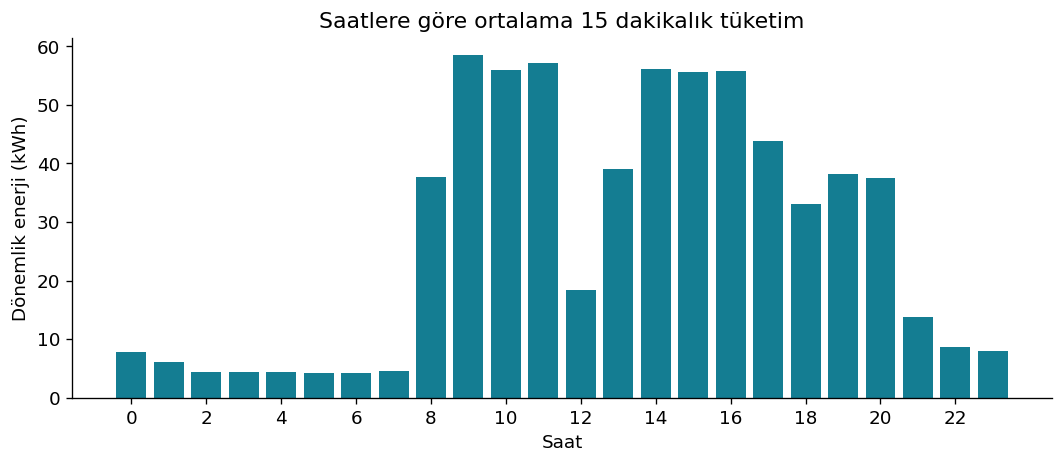

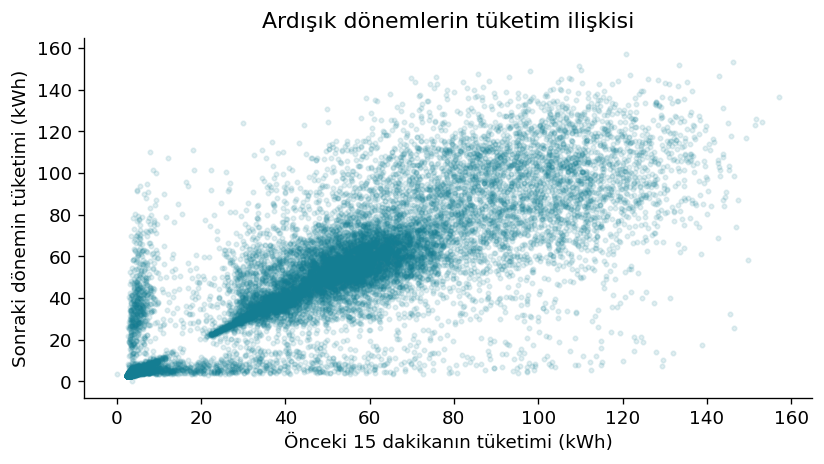

In [5]:
gun_ozeti = veri.groupby(veri.index.dayofweek)['Usage_kWh'].agg(['mean','median','max'])
gun_ozeti.index = ['Pazartesi','Salı','Çarşamba','Perşembe','Cuma','Cumartesi','Pazar']
print('Güne göre dönemlik enerji özeti (kWh):')
print(gun_ozeti.round(2).to_string())
print('Kaynak yük sınıflarının sayıları (modele girdi değil):')
print(veri['Load_Type'].value_counts().to_string())

saat_ozeti = veri.groupby(veri.index.hour)['Usage_kWh'].mean()
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(saat_ozeti.index, saat_ozeti.values, color='#147D92')
ax.set(title='Saatlere göre ortalama 15 dakikalık tüketim',
       xlabel='Saat', ylabel='Dönemlik enerji (kWh)')
ax.set_xticks(range(0,24,2))
fig.tight_layout()
fig.savefig(CIKTI / '01_saatlik_ortalama.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(ozellikler['lag_1'], ozellikler['target_kwh'], s=7, alpha=.12, color='#147D92')
ax.set(title='Ardışık dönemlerin tüketim ilişkisi',
       xlabel='Önceki 15 dakikanın tüketimi (kWh)', ylabel='Sonraki dönemin tüketimi (kWh)')
fig.tight_layout()
fig.savefig(CIKTI / '02_gecmis_iliski.png', dpi=180)
plt.show()


In [6]:
print(f"1. Saatlik ortalama en yüksek: {int(saat_ozeti.idxmax()):02d}:00 "
      f"({saat_ozeti.max():.2f} kWh/dönem).")
print(f"2. Hafta içi ortalama: {veri.loc[veri.index.dayofweek < 5, 'Usage_kWh'].mean():.2f} kWh, "
      f"hafta sonu: {veri.loc[veri.index.dayofweek >= 5, 'Usage_kWh'].mean():.2f} kWh.")
print(f"3. Bir önceki dönemle Pearson korelasyonu: "
      f"{ozellikler['lag_1'].corr(ozellikler['target_kwh']):.3f}.")
print('4. Saçılım grafiğinde ani geçişler var. Tek bir doğrusal model bu geçişleri kaçırabilir.')
print('Bu ilişkiler nedensellik veya kanıtlanmış tasarruf anlamına gelmez.')


1. Saatlik ortalama en yüksek: 09:00 (58.55 kWh/dönem).
2. Hafta içi ortalama: 33.61 kWh, hafta sonu: 11.77 kWh.
3. Bir önceki dönemle Pearson korelasyonu: 0.913.
4. Saçılım grafiğinde ani geçişler var. Tek bir doğrusal model bu geçişleri kaçırabilir.
Bu ilişkiler nedensellik veya kanıtlanmış tasarruf anlamına gelmez.


## Aşama 4 · Model eğitimi
**Model:** `LinearRegression`. Sürekli bir hedefi tahmin ettiği, eğitimi hızlı olduğu
ve katsayıları incelenebildiği için seçildi. Saatin sinüs/kosinüs gösterimi gece yarısındaki
yapay saat sıçramasını azaltır. Negatif tahminleri fiziksel olarak anlamlı olan sıfıra kırparız.

**Bölme:** İlk %80 eğitim, son %20 test. Zaman serisini rastgele karıştırmayız.
Gecikmeleri tüm tabloda oluşturmak, yalnızca geriye bakan `shift` kullandığımız için geleceği sızdırmaz.
Test boyunca her adımda daha önce gerçekleşmiş tüketimin bilindiği **tek adım ileri** tahmini değerlendiririz.
Bu, testin tamamını tek seferde aylar öncesinden tahmin etmek anlamına gelmez.

Karşılaştırma: **süreklilik referansı**, sonraki tüketimi son ölçüme eşit kabul eder.
Model/özellik ayarı için test sonuçlarını kullanmayız. Ayrı hiperparametre araması yoktur.


In [7]:
X = ozellikler.drop(columns='target_kwh')
y = ozellikler['target_kwh']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, shuffle=False)
model = LinearRegression()
model.fit(X_train, y_train)

print('Eğitim X / y boyutları:', X_train.shape, y_train.shape)
print('Test X / y boyutları:', X_test.shape, y_test.shape)
print('Eğitim dönemi:', X_train.index.min(), '/', X_train.index.max())
print('Test dönemi:', X_test.index.min(), '/', X_test.index.max())
print('Katsayılar:')
print(pd.Series(model.coef_, index=X.columns).round(4).to_string())
print('Katsayı büyüklükleri farklı birimler nedeniyle doğrudan önem sırası değildir.')


Eğitim X / y boyutları: (27955, 6) (27955,)
Test X / y boyutları: (6989, 6) (6989,)
Eğitim dönemi: 2018-01-02 00:15:00 / 2018-10-20 04:45:00
Test dönemi: 2018-10-20 05:00:00 / 2019-01-01 00:00:00
Katsayılar:
lag_1       0.8267
lag_4      -0.0267
lag_96      0.1070
hour_sin   -0.4186
hour_cos   -2.6850
weekend    -4.0780
Katsayı büyüklükleri farklı birimler nedeniyle doğrudan önem sırası değildir.


## Aşama 5 · Tahmin ve değerlendirme
**MAE:** Tahminin ortalama mutlak hatası, kWh cinsinden. Düşük olması iyidir.
**RMSE:** Büyük hataları daha fazla cezalandırır. **R²:** Ortalama tahmine göre açıklanan değişimi ölçer.
R² bir sınıflandırma doğruluğu veya yüzde güven değildir.


In [8]:
test_tahmin = np.maximum(model.predict(X_test), 0)
egitim_tahmin = np.maximum(model.predict(X_train), 0)
referans_tahmin = X_test['lag_1'].to_numpy()

def puanla(gercek, tahmin):
    return {'MAE_kWh': mean_absolute_error(gercek, tahmin),
            'RMSE_kWh': np.sqrt(mean_squared_error(gercek, tahmin)),
            'R2': r2_score(gercek, tahmin)}

puanlar = pd.DataFrame({'Doğrusal regresyon': puanla(y_test, test_tahmin),
                       'Son ölçüm referansı': puanla(y_test, referans_tahmin)}).T
print('Test sonuçları:')
print(puanlar.round(4).to_string())
print('Eğitim sonucu:', {k: round(v,4) for k,v in puanla(y_train, egitim_tahmin).items()})
print('MAE bakımından modelin referansa göre değişimi (%):',
      round((1-puanlar.loc['Doğrusal regresyon','MAE_kWh']/
                puanlar.loc['Son ölçüm referansı','MAE_kWh'])*100, 2))
print('Negatif değişim, modelin MAE açısından daha kötü olduğunu gösterir.')
puanlar.to_csv(CIKTI / 'model_sonuclari.csv', encoding='utf-8-sig')

test_sonuclari = pd.DataFrame({'gercek_kwh':y_test,'model_kwh':test_tahmin,
                             'referans_kwh':referans_tahmin})
test_sonuclari.to_csv(CIKTI / 'test_tahminleri.csv', encoding='utf-8-sig')


Test sonuçları:
                     MAE_kWh  RMSE_kWh      R2
Doğrusal regresyon    6.6038   11.6100  0.8632
Son ölçüm referansı   5.4474   12.3314  0.8457
Eğitim sonucu: {'MAE_kWh': 7.5541, 'RMSE_kWh': np.float64(13.4696), 'R2': 0.8425}
MAE bakımından modelin referansa göre değişimi (%): -21.23
Negatif değişim, modelin MAE açısından daha kötü olduğunu gösterir.


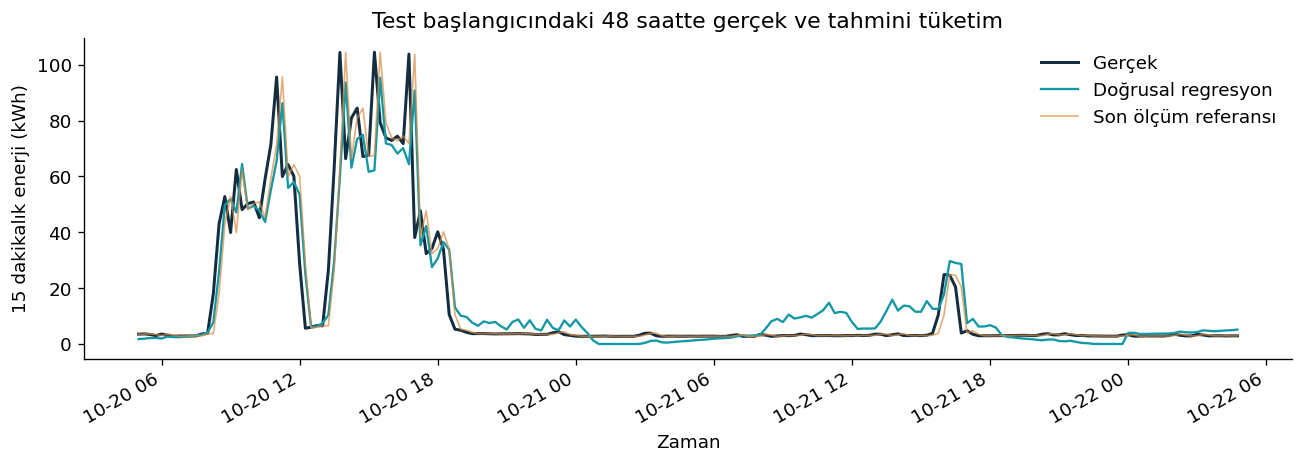

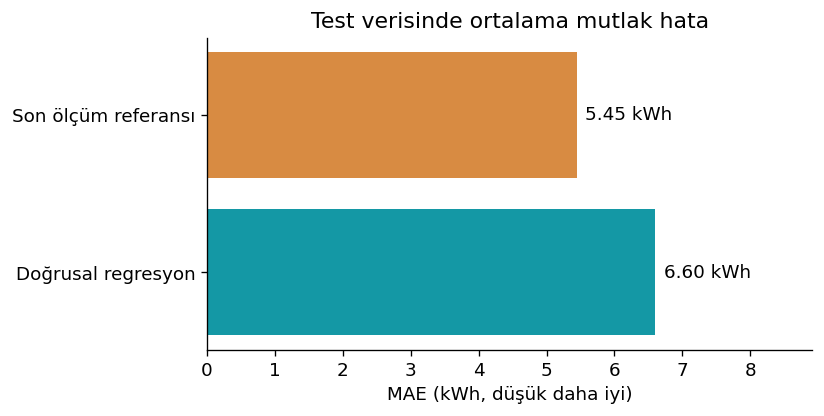

In [9]:
# İlk 192 test kaydını 48 saatlik örnek olarak gösteriyoruz. Bu pencere sonuçtan bağımsızdır.
pencere = test_sonuclari.iloc[:192]
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(pencere.index, pencere['gercek_kwh'], label='Gerçek', color='#142D40', lw=1.8)
ax.plot(pencere.index, pencere['model_kwh'], label='Doğrusal regresyon', color='#1498A5', lw=1.4)
ax.plot(pencere.index, pencere['referans_kwh'], label='Son ölçüm referansı', color='#D88B42', lw=1, alpha=.7)
ax.set(title='Test başlangıcındaki 48 saatte gerçek ve tahmini tüketim',
       xlabel='Zaman', ylabel='15 dakikalık enerji (kWh)')
ax.legend(frameon=False, loc='upper right')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(CIKTI / '03_gercek_tahmin.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7,3.6))
etiketler = ['Doğrusal regresyon','Son ölçüm referansı']
degerler = puanlar.loc[etiketler,'MAE_kWh']
bars = ax.barh(etiketler,degerler,color=['#1498A5','#D88B42'])
ax.bar_label(bars, fmt='%.2f kWh', padding=5)
ax.set(title='Test verisinde ortalama mutlak hata', xlabel='MAE (kWh, düşük daha iyi)', xlim=(0,float(degerler.max())*1.35))
fig.tight_layout()
fig.savefig(CIKTI / '04_mae_karsilastirma.png', dpi=180)
plt.show()


### Sonucun yorumu ve sınırlılıklar
Doğrusal model yüksek bir R² elde etse de MAE bakımından son ölçüm referansını geçemedi.
Bu sonuç, R²'nin tek başına modelin işletme için daha iyi olduğu anlamına gelmediğini gösterir.
Prototipte her iki tahmin de görünür. MAE öncelikliyse eldeki testte referans tercih edilir.

Eğitim/test MAE farkı tek başına belirgin aşırı öğrenmeye işaret etmiyor. Bununla birlikte tek
tesis ve tek yıl, farklı fabrikalara genelleme kanıtı oluşturmaz. Ani üretim geçişleri,
planlı duruşlar ve tatiller modelin zayıf noktalarıdır. Sonraki adımda geçmişe dayalı
yürüyen doğrulama ile üretim takvimi gibi tahmin anında bilinen yeni girdiler incelenebilir.
Tasarruf, arıza önleme veya bütçe uyarısı başarısı sahada ölçülmedi. Bir tahmin aralığı hesaplanmadı.


## Aşama 6 · Akıllı tahmin aracı
`tahmin_et()` hem model tahminini hem son ölçüm referansını gösterir.
**50 kWh**, yalnızca örnek bir 15 dakikalık enerji bütçesidir. İşletmenin gerçek limiti değildir.
Uyarı, model çıktısıyla bu kullanıcı eşiğinin karşılaştırılmasıdır, ayrıca eğitilmiş bir sınıflandırıcı değildir.


In [10]:
def tahmin_et(hedef_zaman, onceki_15dk, bir_saat_once, bir_gun_once, butce_kwh=50):
    """Bilinen geçmiş tüketimlerden bir dönem ileri tahmin ve örnek bütçe uyarısı."""
    t = pd.Timestamp(hedef_zaman)
    degerler = np.asarray([onceki_15dk,bir_saat_once,bir_gun_once,butce_kwh],dtype=float)
    if pd.isna(t) or not np.isfinite(degerler).all() or (degerler < 0).any():
        raise ValueError('Geçerli tarih ve sonlu, negatif olmayan sayılar girin.')
    if t.second != 0 or t.microsecond != 0 or t.nanosecond != 0 or t.minute % 15 != 0:
        raise ValueError('Hedef zaman 15 dakikalık dönem sınırında olmalı.')
    saat = t.hour + t.minute / 60
    girdi = pd.DataFrame([{
        'lag_1':onceki_15dk,'lag_4':bir_saat_once,'lag_96':bir_gun_once,
        'hour_sin':np.sin(2*np.pi*saat/24),'hour_cos':np.cos(2*np.pi*saat/24),
        'weekend':int(t.dayofweek >= 5)}], columns=X.columns)
    # Gerçek kullanımda hedef zaman, son bilinen ölçümden tam 15 dakika sonradır.
    sonuc = max(0.0,float(model.predict(girdi)[0]))
    disarida = any(girdi.iloc[0][c] < X_train[c].min() or
                   girdi.iloc[0][c] > X_train[c].max() for c in ['lag_1','lag_4','lag_96'])
    return {'hedef_zaman':str(t), 'onceki_15dk_kwh':float(onceki_15dk),
            'bir_saat_once_kwh':float(bir_saat_once), 'bir_gun_once_kwh':float(bir_gun_once),
            'model_kwh':round(sonuc,2),'referans_kwh':round(float(onceki_15dk),2),
            'butce_kwh':float(butce_kwh),
            'uyari':'Bütçe aşımı bekleniyor' if sonuc >= butce_kwh else 'Bütçe altında',
            'egitim_araligi_disinda':disarida}

# Bunlar kullanıcı senaryolarıdır. Gerçekleşmiş sonuçları olmadığı için hata puanına katılmaz.
senaryolar = [
    ('2019-01-02 02:00',4.0,4.5,5.0),
    ('2019-01-02 10:00',45.0,40.0,42.0),
    ('2019-01-02 14:00',90.0,85.0,88.0)]
ornekler = pd.DataFrame([tahmin_et(*s) for s in senaryolar])
print(ornekler.round(2).to_string(index=False))
ornekler.to_csv(CIKTI / 'uc_yeni_senaryo.csv',index=False,encoding='utf-8-sig')


        hedef_zaman  onceki_15dk_kwh  bir_saat_once_kwh  bir_gun_once_kwh  model_kwh  referans_kwh  butce_kwh                  uyari  egitim_araligi_disinda
2019-01-02 02:00:00              4.0                4.5               5.0       4.96           4.0       50.0          Bütçe altında                   False
2019-01-02 10:00:00             45.0               40.0              42.0      46.51          45.0       50.0          Bütçe altında                   False
2019-01-02 14:00:00             90.0               85.0              88.0      87.86          90.0       50.0 Bütçe aşımı bekleniyor                   False


In [11]:
# @title İsteğe bağlı kullanıcı girişi
ETKILESIMLI_CALISTIR = False # @param {type:'boolean'}
if ETKILESIMLI_CALISTIR:
    try:
        zaman_girdisi = input('Hedef zaman (örn. 2019-01-02 10:00): ')
        oku = lambda mesaj: float(input(mesaj).strip().replace(',','.'))
        s = tahmin_et(zaman_girdisi,
                      oku('Son 15 dakikanın tüketimi (kWh): '),
                      oku('1 saat önceki dönemin tüketimi (kWh): '),
                      oku('24 saat önceki dönemin tüketimi (kWh): '),
                      oku('Bu dönem için enerji bütçeniz (kWh): '))
        print(f"Sonraki 15 dakika tahmini: {s['model_kwh']:.2f} kWh. "
              f"Son ölçüm referansı: {s['referans_kwh']:.2f} kWh. {s['uyari']}.")
        if s['egitim_araligi_disinda']:
            print('Girdi eğitim aralığının dışında. Tahmin daha belirsiz olabilir.')
    except (ValueError,TypeError) as hata:
        print('Girdi hatası:', hata)
else:
    s = tahmin_et(*senaryolar[2])
    print(f"Örnek çalıştırma: sonraki 15 dakika tahmini {s['model_kwh']:.2f} kWh. "
          f"Son ölçüm referansı {s['referans_kwh']:.2f} kWh. {s['uyari']}.")
    print('Kendi girdileriniz için ETKILESIMLI_CALISTIR kutusunu işaretleyip hücreyi çalıştırın.')


Örnek çalıştırma: sonraki 15 dakika tahmini 87.86 kWh. Son ölçüm referansı 90.00 kWh. Bütçe aşımı bekleniyor.
Kendi girdileriniz için ETKILESIMLI_CALISTIR kutusunu işaretleyip hücreyi çalıştırın.


## Aşama 7 · Dokümantasyon ve teslim
Teslim dosyaları: 5 slaytlık sunum, 1 sayfalık rapor, bu açıklamalı not defteri,
orijinal CSV ve veri sözlüğü. Grafikler, test tahminleri ve üç yeni senaryo `ciktilar` klasörüne kaydedilir.

**Colab bağlantısı oluşturma:** https://colab.research.google.com/ adresinde
`Dosya > Not defteri yükle` ile bu `.ipynb` dosyasını açın. Drive'a bir kopya kaydedin.
`Paylaş` menüsünden uygun görüntüleme erişimini seçip bağlantıyı kopyalayın.
Bu işlem sizin Google hesabınızda gerçekleşir; dosyanın kendisi henüz bir Colab paylaşım bağlantısı değildir.

**Kaynakça:** V E, S., Shin, C., & Cho, Y. (2021). *Steel Industry Energy Consumption* [Dataset].
UCI Machine Learning Repository. https://doi.org/10.24432/C52G8C. CC BY 4.0.
Python uygulaması ve proje uyarlaması: Görkem Vatansever.
